# PRACTICUM DE ÎNVĂȚARE AUTOMATĂ: CODUL ȘI ALGORITMUL KNN
**Teme:** Preprocesarea datelor, Codificare categorială, Normalizare, Algoritmul K cei mai apropiați vecini (KNN), Ajustarea hiperparametrilor, Valori metrice ale distanței, Intel® Extension for Scikit-learn și Combaterea supraantrenării (Overfitting).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, mean_squared_error
from sklearn.datasets import make_moons, make_classification
SEED = 42
df = pd.read_csv(Path('data') / 'Orange_Telecom_Churn_Data.csv')
assert not df.isna().any().any()
X = df.drop(columns=['state', 'area_code', 'phone_number', 'churned']).copy()
for col in ['intl_plan', 'voice_mail_plan']:
    X[col] = X[col].map({'no': 0, 'yes': 1})
y = df['churned'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
def pipeline(k=3, weights='uniform', p=2):
    return Pipeline([('scale', MinMaxScaler()), ('knn', KNeighborsClassifier(n_neighbors=k, weights=weights, p=p))])
print('Dimensiuni:', df.shape, '| Train:', X_train.shape, '| Test:', X_test.shape)
display(y.value_counts().rename(index={0:'Nu renunță',1:'Renunță'}))


Dimensiuni: (5000, 21) | Train: (4000, 17) | Test: (1000, 17)
churned
Nu renunță    4293
Renunță        707
Name: count, dtype: int64


### Exercițiul 1: Ingineria caracteristicilor și eliminarea coloanelor irelevante
În setul de date Orange Telecom Churn, coloanele `state`, `area_code` și `phone_number` au fost eliminate în notebook. Scrieți un bloc de cod în Pandas care analizează cardinalitatea unică a fiecărei coloane categoriale rămase și eliminate. Explicați din punct de vedere matematic de ce aplicarea `OneHotEncoder` sau `LabelBinarizer` pe o coloană cu sute de valori unice (de exemplu, `phone_number`) va distruge eficiența spațială și va genera un risc ridicat de supraantrenare (overfitting) pentru algoritmul KNN.

In [2]:
cats = list(df.select_dtypes(include=['object', 'bool']).columns)
cats = list(dict.fromkeys(cats + ['area_code']))
card = pd.DataFrame({'valori_unice': df[cats].nunique(), 'proporție_unică': df[cats].nunique()/len(df)})
card['eliminată'] = card.index.isin(['state','area_code','phone_number'])
display(card)
print('Coloane suplimentare One-Hot:', int(card.valori_unice.sum()))


,valori_unice,proporție_unică,eliminată
state,51,0.0102,True
phone_number,5000,1.0000,True
intl_plan,2,0.0004,False
voice_mail_plan,2,0.0004,False
churned,2,0.0004,False
area_code,3,0.0006,True


C:\Users\Asus\Pictures\si-app\laborator_knn\01_Laborator_KNN_rezolvat.ipynb:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  {
Coloane suplimentare One-Hot: 5060


**Explicație.** Pentru $n$ obiecte și $m$ categorii, codificarea densă cere $O(nm)$ memorie (float64: $8nm$ octeți); o reprezentare rară reduce stocarea, dar nu elimină dimensionalitatea. Pentru două numere de telefon distincte, vectorii one-hot au distanța $\sqrt{2}$, indiferent de asemănarea reală dintre clienți. Identificatorii nu oferă vecini utili pentru clienți noi și favorizează memorarea. `state` și `area_code` pot conține informație geografică utilă; eliminarea lor este alegerea laboratorului, nu o regulă universală.

### Exercițiul 2: Impactul scalării datelor asupra distanței euclidiene
Folosind `MinMaxScaler`, toate caracteristicile numerice sunt aduse în intervalul [0, 1]. Să presupunem că avem două caracteristici: `account_length` (valori de la 1 la 250) și `total_day_charge` (valori de la 0 la 100). Calculați manual sau scrieți cod care arată cum distanța euclidiană între doi clienți este distorsionată dacă nu se aplică scalarea. Ce se întâmplă dacă se folosește `StandardScaler` în loc de `MinMaxScaler` atunci când în distribuția datelor există valori anormale (outliers)?

In [3]:
points = np.array([[1.,0.],[250.,100.]])
delta = points[1]-points[0]
print('Distanța brută:', np.linalg.norm(delta))
print('Contribuții pătratice:', delta**2 / np.sum(delta**2))
print('Distanța MinMax:', np.linalg.norm(MinMaxScaler().fit_transform(points)[1]))
outliers = np.array([[1.],[2.],[3.],[4.],[100.]])
display(pd.DataFrame({'original':outliers.ravel(), 'MinMax':MinMaxScaler().fit_transform(outliers).ravel(),
                      'Standard':StandardScaler().fit_transform(outliers).ravel()}))


,original,MinMax,Standard
0,1.0,0.000000,-0.538285
1,2.0,0.010101,-0.512652
2,3.0,0.020202,-0.487019
3,4.0,0.030303,-0.461387
4,100.0,1.000000,1.999343


Distanța brută: 268.33002068348594
Contribuții pătratice: [0.86111304 0.13888696]
Distanța MinMax: 1.414213562373095


**Explicație.** Distanța brută este $\sqrt{249^2+100^2}$; `account_length` contribuie aproximativ 86% din pătratul distanței. După scalarea cu limitele enunțului, diferențele sunt (1,1), iar distanța este $\sqrt2$. MinMax comprimă valorile obișnuite când un outlier extinde intervalul. StandardScaler folosește $(x-\mu)/\sigma$, dar media și deviația standard sunt și ele sensibile la outlieri; nu este o soluție robustă și nu garantează [0,1]. RobustScaler poate fi o alternativă. În evaluări, scalerul se ajustează doar pe train.

### Exercițiul 3: Optimizare hardware cu Intel® Extension for Scikit-learn
În notebook este activată extensia `from sklearnex import patch_sklearn; patch_sklearn()`. Explicați cum această bibliotecă accelerează operațiunile de căutare a celor mai apropiați vecini (de exemplu, utilizând structuri de date indexate precum KD-Tree sau Ball-Tree, optimizate cu instrucțiuni AVX-512). Scrieți un fragment de cod care măsoară timpul de execuție (`timeit`) pentru antrenarea `KNeighborsClassifier` cu și fără patch-ul Intel pe un set sintetic de 100.000 de obiecte.

In [4]:
import timeit
import importlib.util
rng = np.random.default_rng(SEED)
X_bench = rng.random((100000,10), dtype=np.float64)
y_bench = rng.integers(0,2,100000)
if importlib.util.find_spec('sklearnex') is None:
    from sklearn.neighbors import KNeighborsClassifier as BaseKNN
    t = min(timeit.repeat(lambda: BaseKNN(3, algorithm='brute', n_jobs=1).fit(X_bench,y_bench), repeat=3, number=1))
    print(f'Fără patch, fit: {t:.6f} s')
    print('sklearnex nu este instalat: comparația Intel nu a fost executată. Instalați scikit-learn-intelex și rerulați.')
else:
    from sklearnex import patch_sklearn, unpatch_sklearn
    rows = []
    try:
        for patched in [False, True]:
            if patched: patch_sklearn()
            else: unpatch_sklearn()
            from sklearn.neighbors import KNeighborsClassifier as BenchKNN
            model = BenchKNN(3, algorithm='brute', n_jobs=1)
            fit_s = min(timeit.repeat(lambda: model.fit(X_bench,y_bench), repeat=3, number=1))
            model.fit(X_bench,y_bench)
            pred_s = min(timeit.repeat(lambda: model.predict(X_bench[:100]), repeat=3, number=1))
            rows.append({'Intel':patched, 'fit_s':fit_s,'predict_100_s':pred_s})
        display(pd.DataFrame(rows))
    finally:
        unpatch_sklearn()


Fără patch, fit: 0.006560 s
sklearnex nu este instalat: comparația Intel nu a fost executată. Instalați scikit-learn-intelex și rerulați.


**Explicație.** Extensia poate înlocui implementări compatibile cu backend-uri oneDAL optimizate, folosind vectorizare SIMD și paralelizare. AVX-512 depinde de procesor; nu presupunem că este disponibil. KD-Tree/Ball-Tree nu sunt automat explicația accelerării: suportul depinde de versiune, metrică și algoritm, iar căutarea brute-force poate fi optimizată. KNN este lazy learning: fit poate doar stoca datele; măsurăm separat predicția. Timpii sunt locali și nu demonstrează o accelerare universală.

### Exercițiul 4: Analiza matematică a metricilor de distanță (Minkowski, Manhattan, Euclidiană)
Implementați de la zero o funcție Python care calculează distanța Minkowski între două puncte $x$ și $y$ pentru o putere arbitrară $p \ge 1$. Demonstrați prin cod cum modificarea parametrului `p` de la 1 (Manhattan) la 2 (Euclidiană) și la valori mari ($p \to \infty$, distanța Cebîșev) influențează granițele de decizie ale clasificatorului KNN pe un set de date binar bidimensional.

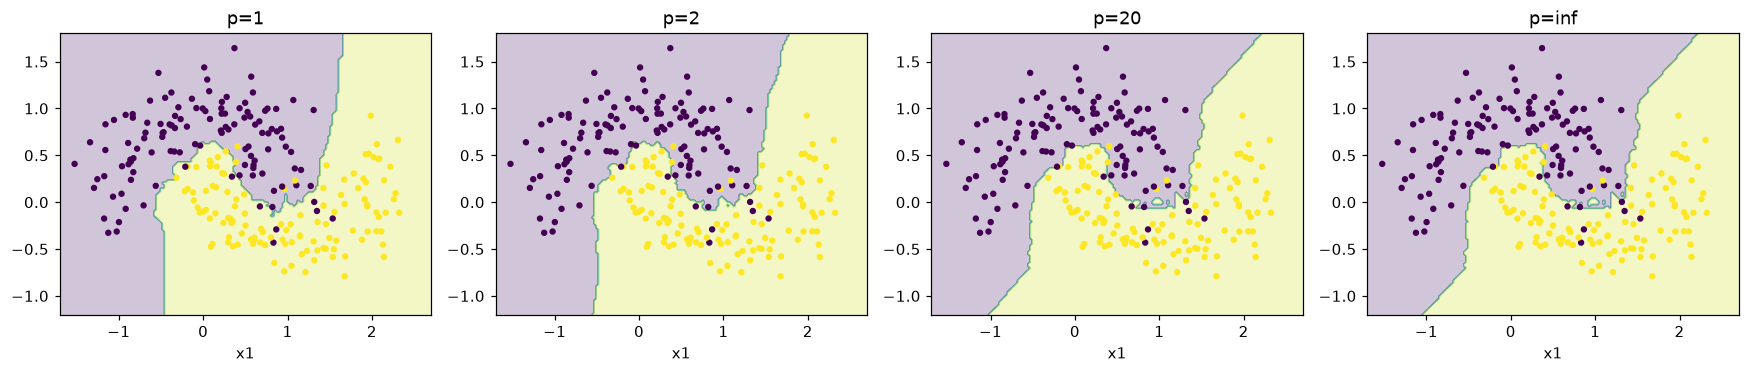

1 7.0
2 5.0
20 4.000633288976906
inf 4.0


In [5]:
def minkowski_distance(x, y, p):
    a, b = np.asarray(x,dtype=float), np.asarray(y,dtype=float)
    if a.shape != b.shape or a.size == 0: raise ValueError('Forme incompatibile sau vectori goi')
    if np.isnan(p) or p < 1: raise ValueError('p trebuie să fie >= 1')
    d = np.abs(a-b)
    if np.isinf(p): return float(d.max())
    m = d.max()
    return 0. if m == 0 else float(m*np.sum((d/m)**p)**(1/p))
for p in [1,2,20,np.inf]: print(p, minkowski_distance([0,0],[3,4],p))
assert minkowski_distance([0,0],[3,4],2) == 5
Xm, ym = make_moons(n_samples=240, noise=.23, random_state=SEED)
gx, gy = np.meshgrid(np.linspace(-1.7,2.7,180), np.linspace(-1.2,1.8,140))
grid = np.c_[gx.ravel(),gy.ravel()]
fig, axes = plt.subplots(1,4,figsize=(16,3.5))
for ax,p in zip(axes,[1,2,20,np.inf]):
    args = {'metric':'chebyshev'} if np.isinf(p) else {'metric':'minkowski','p':p}
    model = KNeighborsClassifier(9, algorithm='brute', **args).fit(Xm,ym)
    ax.contourf(gx,gy,model.predict(grid).reshape(gx.shape),alpha=.25)
    ax.scatter(*Xm.T,c=ym,s=10); ax.set_title(f'p={p}'); ax.set_xlabel('x1')
plt.tight_layout(); plt.show()


**Explicație.** $d_p(x,y)=(\sum_j|x_j-y_j|^p)^{1/p}$. Pentru p=1 bilele sunt romburi, pentru p=2 cercuri, iar la limita infinit pătrate în 2D. Ponderarea diferită a componentelor schimbă ordinea vecinilor și frontierele; graficul păstrează aceleași date și K pentru toate metricile.

### Exercițiul 5: Paradoxul preciziei de 100% la K=3 pe eșantionul de antrenare
Așa cum s-a menționat în întrebarea 5 a notebook-ului, rularea KNN cu parametrul `weights='distance'` sau $K=1$ pe setul complet de date (fără împărțire train/test) oferă o precizie de 1.0 (100%). Explicați în detaliu fenomenul de memorare (supraantrenare extremă) în KNN. Ce se întâmplă cu cel mai apropiat vecin al punctului $x_i$ dacă eșantionul de antrenare include chiar punctul $x_i$?

In [6]:
for k,w in [(1,'uniform'),(3,'uniform'),(3,'distance')]:
    model = pipeline(k,w).fit(X_train,y_train)
    print(k,w,'train=',round(model.score(X_train,y_train),4),'test=',round(model.score(X_test,y_test),4))


1 uniform train= 1.0 test= 0.878
3 uniform train= 0.943 test= 0.894
3 distance train= 1.0 test= 0.894


Punctul analizat este propriul său vecin, la distanța zero. La K=1, eticheta sa este reprodusă. Cu weights='distance', scikit-learn acordă voturile vecinilor la distanță zero, excluzând vecinii cu distanță pozitivă din votul respectiv. Astfel apare frecvent acuratețea 1 pe train, inclusiv la K=3. Duplicatele identice cu etichete contradictorii pot împiedica 100%. K=3 cu vot uniform nu garantează 100%. Scorul pe train nu estimează generalizarea; chiar 100% pe train nu dovedește singur cât de mare este supraantrenarea.

### Exercițiul 6: Implementarea propriului algoritm KNN de la zero
Fără a folosi clase din `sklearn`, scrieți propria clasă Python `CustomKNN` care implementează interfețele `fit(X, y)` și `predict(X_test, k)`. Clasa trebuie să utilizeze distanța euclidiană, să suporte votul majoritar simplu și să proceseze eficient matrici NumPy. Testați clasa pe o submulțime mică de date privind abandonul (churn).

In [7]:
class CustomKNN:
    def fit(self, X, y):
        a, b = np.asarray(X,dtype=float), np.asarray(y)
        if a.ndim != 2 or b.ndim != 1 or len(a) != len(b) or not len(a):
            raise ValueError('Date de antrenare invalide')
        if not np.isfinite(a).all(): raise ValueError('Date nefinite')
        self.X_train = a.copy()
        self.classes_, self.y_codes = np.unique(b,return_inverse=True)
        return self
    def predict(self, X_test, k=3):
        if not hasattr(self,'X_train'): raise ValueError('Apelați fit mai întâi')
        q = np.asarray(X_test,dtype=float)
        if q.ndim != 2 or q.shape[1] != self.X_train.shape[1] or not np.isfinite(q).all():
            raise ValueError('Date de test invalide')
        if not isinstance(k,(int,np.integer)) or not 1 <= k <= len(self.X_train):
            raise ValueError('k invalid')
        result = []
        for start in range(0,len(q),128):
            batch = q[start:start+128]
            d2 = ((batch[:,None,:]-self.X_train[None,:,:])**2).sum(axis=2)
            idx = np.argsort(d2,axis=1,kind='stable')[:,:k]
            for neighbors in idx:
                votes = np.bincount(self.y_codes[neighbors], minlength=len(self.classes_))
                result.append(self.classes_[np.argmax(votes)])
        return np.asarray(result,dtype=self.classes_.dtype)
scaler = MinMaxScaler().fit(X_train.iloc[:400])
small_train = scaler.transform(X_train.iloc[:400]); small_test = scaler.transform(X_test.iloc[:100])
custom = CustomKNN().fit(small_train,y_train.iloc[:400])
pred_custom = custom.predict(small_test,3)
print('Accuracy CustomKNN:',accuracy_score(y_test.iloc[:100],pred_custom))
ref = KNeighborsClassifier(3,algorithm='brute').fit(small_train,y_train.iloc[:400]).predict(small_test)
print('Acord cu sklearn:',np.mean(pred_custom==ref))
assert np.array_equal(CustomKNN().fit([[0],[10]],[0,1]).predict([[1],[9]],1),[0,1])


Accuracy CustomKNN: 0.89
Acord cu sklearn: 1.0


**Explicație.** Clasa folosește numai NumPy pentru învățare și predicție. Rădăcina pătrată nu este necesară pentru ordonarea distanțelor euclidiene. Procesarea pe loturi limitează memoria temporară; complexitatea căutării rămâne O(n_test · n_train · d). Egalitatea voturilor este rezolvată prin prima clasă în ordinea np.unique, iar distanțele egale prin ordinea de antrenare.

### Exercițiul 7: Validare încrucișată (Cross-Validation) pentru alegerea K-ului optim
Pentru a evita capcana evaluării pe eșantionul de antrenare, implementați procedura 5-Fold Cross-Validation utilizând `StratifiedKFold` din Scikit-learn. Scrieți un script care calculează precizia medie și deviația standard pentru valori K de la 1 la 30. Generați un grafic al erorilor de validare în funcție de K și determinați valoarea optimă.

,k,accuracy_mean,accuracy_std
0,1,0.87775,0.005668
1,2,0.89175,0.005397
2,3,0.90625,0.004108
3,4,0.89675,0.007272
4,5,0.90500,0.007416
5,6,0.89475,0.005612
6,7,0.90375,0.005969
7,8,0.89200,0.003221
8,9,0.90000,0.004183
9,10,0.89175,0.003588


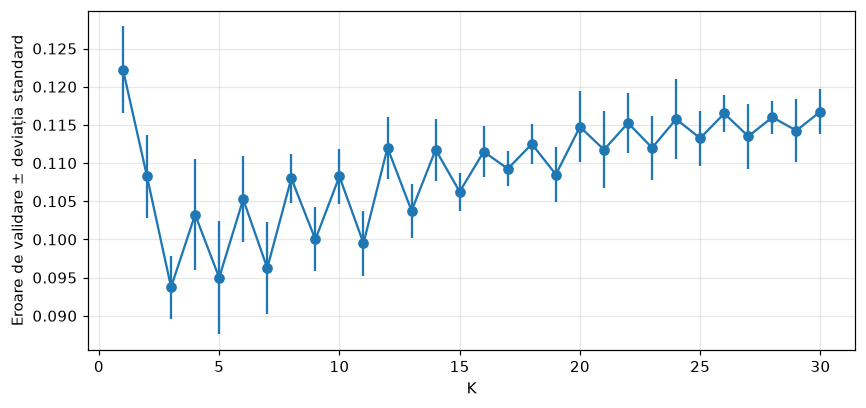

K optim după accuracy CV: 3


In [8]:
rows = []
for k in range(1,31):
    scores = cross_val_score(pipeline(k),X_train,y_train,cv=cv,scoring='accuracy',n_jobs=1)
    rows.append((k,scores.mean(),scores.std()))
cv_results = pd.DataFrame(rows,columns=['k','accuracy_mean','accuracy_std'])
best_k = int(cv_results.loc[cv_results.accuracy_mean.idxmax(),'k'])
display(cv_results); print('K optim după accuracy CV:',best_k)
plt.figure(figsize=(9,4)); plt.errorbar(cv_results.k,1-cv_results.accuracy_mean,yerr=cv_results.accuracy_std,fmt='o-')
plt.xlabel('K'); plt.ylabel('Eroare de validare ± deviația standard'); plt.grid(alpha=.3); plt.show()


**Explicație.** Fiecare fold ajustează propriul scaler exclusiv pe partea sa de antrenare. Alegem K pe train prin 5 folduri stratificate; testul este rezervat evaluării. La egalitate se selectează cel mai mic K. Barele reprezintă deviația standard între folduri, nu un interval de încredere.

### Exercițiul 8: Lucrul cu clase dezechilibrate (Class Imbalance)
În setul de date Orange Telecom, clasa majoritară este reprezentată de clienții care nu au renunțat (`churned = False`), iar cei care au renunțat reprezintă minoritatea. Explicați de ce metrica `accuracy` (acuratețea) în acest context este înșelătoare. Modificați codul de evaluare pentru a calcula Matricea de Confuzie (Confusion Matrix), Precision, Recall și F1-score utilizând `sklearn.metrics`.

In [9]:
model_cv = pipeline(best_k).fit(X_train,y_train)
pred = model_cv.predict(X_test)
print('Accuracy clasă majoritară:',accuracy_score(y_test,np.zeros(len(y_test),dtype=int)))
display(pd.DataFrame(confusion_matrix(y_test,pred),index=['Real 0','Real 1'],columns=['Prezis 0','Prezis 1']))
print(classification_report(y_test,pred,target_names=['Nu renunță','Renunță'],zero_division=0))


,Prezis 0,Prezis 1
Real 0,834,25
Real 1,81,60


Accuracy clasă majoritară: 0.859
              precision    recall  f1-score   support

  Nu renunță       0.91      0.97      0.94       859
     Renunță       0.71      0.43      0.53       141

    accuracy                           0.89      1000
   macro avg       0.81      0.70      0.74      1000
weighted avg       0.88      0.89      0.88      1000



**Explicație.** Un model care prezice numai clasa majoritară poate avea accuracy mare, dar recall=0 pentru churn. Pentru clasa pozitivă: precision=TP/(TP+FP), recall=TP/(TP+FN), F1=2PR/(P+R). Matricea are linii reale și coloane prezise. Alegerea metricii depinde de costul clienților pierduți față de alarmele false.

### Exercițiul 9: Impactul ponderilor distanței (`weights='distance'`) versus ponderi uniforme
Comparați comportamentul modelului KNN pentru `weights='uniform'` și `weights='distance'`. Scrieți un experiment în Python care evaluează sensibilitatea modelului la zgomot (valori anormale în spațiul caracteristicilor) pentru ambele tipuri de ponderi. Care variantă este mai vulnerabilă la zgomot și de ce?

In [10]:
rng = np.random.default_rng(SEED)
sc = MinMaxScaler().fit(X_train)
A, B = sc.transform(X_train), sc.transform(X_test)
noise_rows=[]
for seed in range(5):
    r = np.random.default_rng(seed)
    far = A.copy(); chosen = r.choice(len(A),size=int(.05*len(A)),replace=False)
    far[chosen] += r.normal(0,5,far[chosen].shape)
    # Puncte perturbate lângă exemple reale, cu etichete inversate.
    near = A[chosen] + r.normal(0,.005,A[chosen].shape)
    for kind,train_a,train_y in [('curat',A,y_train.to_numpy()),('outlieri',far,y_train.to_numpy()),
                               ('zgomot local',np.vstack([A,near]),np.r_[y_train.to_numpy(),1-y_train.to_numpy()[chosen]])]:
        for w in ['uniform','distance']:
            m = KNeighborsClassifier(7,weights=w).fit(train_a,train_y)
            z=m.predict(B)
            noise_rows.append((seed,kind,w,accuracy_score(y_test,z),f1_score(y_test,z)))
noise_results=pd.DataFrame(noise_rows,columns=['seed','date','weights','accuracy','f1'])
display(noise_results.groupby(['date','weights'])[['accuracy','f1']].agg(['mean','std']))


accuracy                  f1          
                          mean       std      mean       std
date         weights                                        
curat        distance   0.9030  0.000000  0.540284  0.000000
             uniform    0.9030  0.000000  0.540284  0.000000
outlieri     distance   0.9024  0.003286  0.537706  0.020083
             uniform    0.9026  0.002966  0.538198  0.019384
zgomot local distance   0.9034  0.002608  0.547291  0.013693
             uniform    0.9036  0.002793  0.547814  0.014058

**Explicație.** Nu există o variantă universal mai vulnerabilă. Un vecin foarte apropiat etichetat greșit poate domina votul ponderat prin 1/d; votul uniform îi limitează influența la un vot. În schimb, ponderarea poate reduce influența unor vecini îndepărtați. Outlierii foarte îndepărtați pot să nu intre deloc în cei K vecini. Experimentul compară aceleași perturbări pentru ambele variante și păstrează testul curat.

### Exercițiul 10: Blestemul dimensionalității (Curse of Dimensionality)
Algoritmul KNN se bazează pe măsurarea distanțelor în spații multidimensionale. Odată cu creșterea numărului de caracteristici, volumul spațiului crește exponențial, iar punctele devin echidistante. Scrieți un studiu de caz sau un experiment mic în Python care arată cum creșterea artificială a dimensionalității (adăugarea de coloane cu zgomot aleatoriu la datele de churn) înrăutățește performanța clasificatorului KNN.

,accuracy,f1,contrast
zgomot,,,
0,0.903000,0.540284,7.213865
5,0.875333,0.283011,3.828497
20,0.858333,0.151036,1.690386
50,0.858667,0.081760,0.789821
100,0.855333,0.035353,0.509771
200,0.857000,0.035891,0.334868


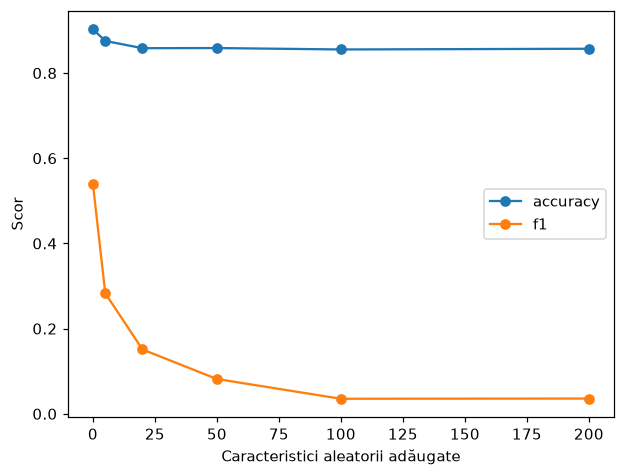

In [11]:
dim_rows=[]
for seed in range(3):
    rng=np.random.default_rng(seed)
    Ntr=rng.random((len(A),200)); Nte=rng.random((len(B),200))
    for d in [0,5,20,50,100,200]:
        tr=np.c_[A,Ntr[:,:d]]; te=np.c_[B,Nte[:,:d]]
        m=KNeighborsClassifier(7).fit(tr,y_train); z=m.predict(te)
        distances=np.linalg.norm(tr-te[0],axis=1)
        contrast=(distances.max()-distances.min())/distances.min()
        dim_rows.append((seed,d,accuracy_score(y_test,z),f1_score(y_test,z),contrast))
dim_results=pd.DataFrame(dim_rows,columns=['seed','zgomot','accuracy','f1','contrast'])
display(dim_results.groupby('zgomot')[['accuracy','f1','contrast']].mean())
dim_results.groupby('zgomot')[['accuracy','f1']].mean().plot(marker='o',ylabel='Scor',xlabel='Caracteristici aleatorii adăugate'); plt.show()


**Explicație.** Coordonatele independente de etichetă contribuie la distanță fără informație predictivă. Pentru un număr fix de observații, vecinii devin mai puțin relevanți, iar distanțele se concentrează relativ. Contrastul este (d_max−d_min)/d_min pentru primul punct de test. Urmărim și F1, deoarece accuracy poate rămâne aproape de baseline-ul majoritar. Tendința este statistică, nu obligatoriu monotonă la fiecare pas.

### Exercițiul 11: KNN pentru regresie versus clasificare
Deși în notebook am folosit `KNeighborsClassifier` pentru o sarcină de clasificare binară, KNN este aplicabil și pentru regresie (`KNeighborsRegressor`). Scrieți un script care aplică `KNeighborsRegressor` pentru a prezice o variabilă continuă (de exemplu, `total_day_charges` pe baza minutelor și a apelurilor). Comparați funcția de pierdere (MSE — Mean Squared Error) pentru diferite valori ale lui K.

,k,CV_MSE
0,1,0.177691
1,3,0.125157
2,5,0.132903
3,7,0.157206
4,9,0.178956
5,11,0.206309
6,15,0.263939
7,21,0.354140


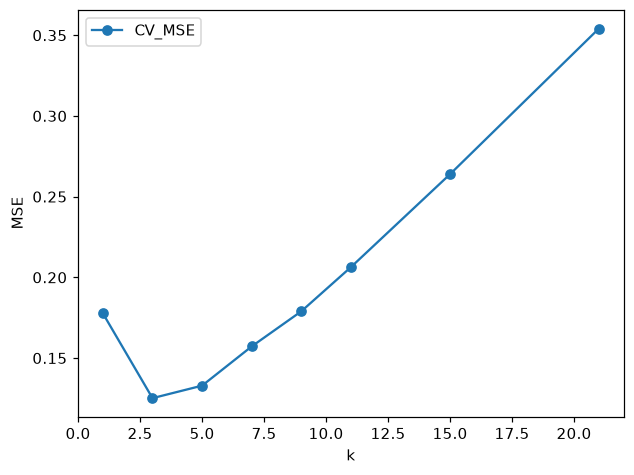

K ales: 3 | MSE test: 1.0102697888888892


In [12]:
features = ['total_day_minutes','total_day_calls']
target = 'total_day_charge'
rx_train,rx_test,ry_train,ry_test=train_test_split(df[features],df[target],test_size=.2,random_state=SEED)
reg_rows=[]
for k in [1,3,5,7,9,11,15,21]:
    reg=Pipeline([('scale',MinMaxScaler()),('knn',KNeighborsRegressor(k))])
    mse_cv=-cross_val_score(reg,rx_train,ry_train,cv=5,scoring='neg_mean_squared_error').mean()
    reg_rows.append((k,mse_cv))
reg_scores=pd.DataFrame(reg_rows,columns=['k','CV_MSE']); display(reg_scores)
reg_k=int(reg_scores.loc[reg_scores.CV_MSE.idxmin(),'k'])
reg=Pipeline([('scale',MinMaxScaler()),('knn',KNeighborsRegressor(reg_k))]).fit(rx_train,ry_train)
print('K ales:',reg_k,'| MSE test:',mean_squared_error(ry_test,reg.predict(rx_test)))
reg_scores.plot(x='k',y='CV_MSE',marker='o',ylabel='MSE'); plt.show()


**Explicație.** Clasificarea utilizează votul, regresia media valorilor vecinilor. MSE este media pătratelor erorilor și se exprimă în unități monetare la pătrat. K se alege prin CV, apoi evaluăm o singură dată pe test. În acest set, taxa de zi este aproximativ 0,17 × minutele de zi (cu rotunjire); problema este aproape deterministă și nu reprezintă o prognoză dificilă. Coloana corectă este total_day_charge, la singular.

### Exercițiul 12: Conducte de învățare automată cu `Pipeline` și `GridSearchCV`
Construiți o conductă (pipeline) completă în Scikit-learn care include: (1) `MinMaxScaler`, (2) opțional un selector de caracteristici (`SelectKBest`) și (3) `KNeighborsClassifier`. Utilizați `GridSearchCV` pentru căutarea simultană a hiperparametrilor optimi: numărul de vecini K din {3, 5, 7, 9, 11}, tipul de ponderi (`uniform`, `distance`) și metrica distanței (p=1 sau p=2). Afișați cel mai bun set de hiperparametri și scorul pe eșantionul de test.

In [13]:
from sklearn.feature_selection import SelectKBest, f_classif
pipe=Pipeline([('scale',MinMaxScaler()),('select','passthrough'),('knn',KNeighborsClassifier())])
grid={'knn__n_neighbors':[3,5,7,9,11], 'knn__weights':['uniform','distance'], 'knn__p':[1,2]}
# Selectorul este opțional; îl comparăm cu folosirea tuturor caracteristicilor.
param_grid=[dict(grid,select=['passthrough']), dict(grid,select=[SelectKBest(f_classif)],select__k=[10])]
search=GridSearchCV(pipe,param_grid,cv=cv,scoring={'accuracy':'accuracy','f1':'f1'},refit='f1',n_jobs=1)
search.fit(X_train,y_train)
print('Hiperparametri optimi:',search.best_params_)
print('F1 mediu CV:',search.best_score_)
final_pred=search.predict(X_test)
print('Accuracy test:',accuracy_score(y_test,final_pred))
print(classification_report(y_test,final_pred,zero_division=0))


Hiperparametri optimi: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform', 'select': SelectKBest(), 'select__k': 10}
F1 mediu CV: 0.6561249674799507
Accuracy test: 0.907
              precision    recall  f1-score   support

           0       0.92      0.98      0.95       859
           1       0.77      0.49      0.60       141

    accuracy                           0.91      1000
   macro avg       0.84      0.73      0.77      1000
weighted avg       0.90      0.91      0.90      1000



**Explicație.** Pipeline păstrează scalarea și selecția în interiorul fiecărui fold. GridSearchCV compară 40 de configurații, fiecare pe 5 folduri. Optimizăm F1 pentru clasa minoritară și raportăm și accuracy; de aceea K poate diferi de exercițiul 7. Scorurile pe test din exercițiile precedente sunt ilustrative: nu folosim testul pentru alegerea parametrilor finali.

## Concluzii pe datele executate

Setul are 5.000 de clienți, 17 caracteristici păstrate și 707 cazuri de churn (14,14%). Au fost rezervate 1.000 de observații pentru test. Baseline-ul majoritar pe test este 85,9%.

Validarea după accuracy a ales K=3; modelul obține 89,4% accuracy pe test, dar recall-ul clasei churn este numai aproximativ 43%. GridSearchCV optimizat după F1 a ales K=5, p=2, vot uniform și 10 caracteristici selectate. Accuracy pe test este 90,7%, cu F1 pentru churn aproximativ 0,60 și recall aproximativ 49%. Așadar, acuratețea singură ascunde aproape jumătate dintre clienții care renunță.

CustomKNN a avut aceleași predicții ca implementarea sklearn pe cele 100 de exemple de test ale experimentului. Pentru regresie, CV a ales K=3, cu MSE pe test aproximativ 1,0103. Rezultatele depind de împărțirea fixată și nu sunt o garanție pentru date noi.

Comparația de performanță cu Intel rămâne de executat într-un mediu cu `scikit-learn-intelex`; timpul fără patch este măsurat, iar timpul cu patch nu este inventat.